# Pipeline CPU n°1 — PyTorch → ONNX → OpenVINO Runtime → CPU

**TP Déploiement IA — analyse comparative de pipelines de déploiement (CPU / GPU)**

| Couche | Dans ce notebook |
|---|---|
| Haut niveau | PyTorch — ResNet-18 pré-entraîné ImageNet |
| Format du modèle | ONNX (graphe statique, batch de 10) |
| Middle level | OpenVINO Runtime : conversion en IR, fusion d'opérateurs, choix des kernels |
| Bas niveau | kernels CPU optimisés oneDNN (AVX2 / AVX-512 selon le processeur) |
| Matériel | CPU Google Colab |

**Environnement Colab : CPU** (*Exécution > Modifier le type d'exécution*), puis *Exécution > Tout exécuter*.

**Variantes mesurées dans ce notebook**
- `pytorch_eager` — PyTorch eager FP32 (référence, même CPU)
- `onnxruntime` — même fichier ONNX exécuté par ONNX Runtime (variante de contrôle : isole l'effet du runtime)
- `openvino` — **pipeline étudié** : OpenVINO Runtime FP32

## 0. Installation

In [1]:
!pip install -q openvino onnx onnxscript onnxruntime

In [2]:
# Identifiant du pipeline (seule cellule de configuration propre à ce notebook)
PIPELINE_ID = "cpu1_openvino"
PIPELINE_LABEL = "CPU 1 · PyTorch → ONNX → OpenVINO"
PLATFORM = "CPU"
PIPELINE_LAYERS = {
    "haut_niveau": "PyTorch",
    "format": "ONNX",
    "middle_level": "OpenVINO Runtime",
    "bas_niveau": "oneDNN (kernels CPU)",
    "materiel": "CPU Google Colab",
}

## 1. Protocole expérimental commun

Les cellules « COMMUNE » ci-dessous sont **strictement identiques dans les 4 notebooks** : mêmes données, même prétraitement, même modèle, même méthode de mesure.

| Élément | Choix |
|---|---|
| Données | 50 images du jeu de test CIFAR-10 : les 5 premières de chaque classe (sous-ensemble équilibré et déterministe ; indices et empreintes SHA-256 enregistrés) |
| Prétraitement | 32×32 → 224×224 (bilinéaire), puis normalisation ImageNet (moyenne 0,485 / 0,456 / 0,406 ; écart-type 0,229 / 0,224 / 0,225) |
| Modèle | ResNet-18 torchvision, poids `IMAGENET1K_V1`, sans réentraînement |
| Top-1 sur 10 classes | les 1000 classes ImageNet sont regroupées en 10 super-classes CIFAR-10 (somme des probabilités softmax), prédiction = argmax des 10 scores |
| Performances | batch de 10 (5 batchs), 10 batchs de chauffe, puis **10 exécutions** chronométrées du passage complet ; chaque batch est chronométré avec synchronisation du GPU ; les données sont déjà en mémoire du device |
| Statistiques | moyenne, écart-type, minimum, maximum et coefficient de variation (CV = écart-type / moyenne) |
| Énergie | GPU : NVML (énergie de la carte) ; CPU : Intel RAPL si la VM l'expose (rarement sur Colab) ; fenêtres d'au moins 5 s |
| Référence | chaque notebook mesure aussi **PyTorch eager FP32 sur le même matériel** : accélérations et écarts de prédiction sont calculés dans les mêmes conditions |

In [3]:
# ============ CELLULE COMMUNE 1/6 : imports, paramètres expérimentaux, environnement ============
# (identique dans les 4 notebooks : ne modifier qu'ici, et de la même façon partout)
import os, sys, gc, re, glob, json, time, copy, hashlib, platform, datetime, threading, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

SEED = 0
IMAGES_PER_CLASS = 5        # 5 images x 10 classes = 50 images (sous-ensemble équilibré et déterministe)
BATCH_SIZE = 10             # même taille de batch pour les 4 pipelines : 50 images = 5 batchs
N_WARMUP = 10               # batchs de chauffe, non chronométrés
N_RUNS = 10                 # exécutions chronométrées du passage complet sur les 50 images (>= 3 exigées)
ENERGY_WINDOW_S = 5.0       # durée minimale d'une fenêtre de mesure énergétique (résolution des capteurs)
N_ENERGY_RUNS = 3           # répétitions de la mesure énergétique
IDLE_WINDOW_S = 2.0         # mesure de la puissance au repos (avant chaque série)
IMG_SIZE = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
RESULTS_DIR, FIGURES_DIR = "results", "figures"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if PLATFORM == "GPU" else "cpu"
if DEVICE == "cuda":
    assert torch.cuda.is_available(), "Aucun GPU détecté : Exécution > Modifier le type d'exécution > GPU (T4)."
    torch.backends.cudnn.benchmark = True   # formes fixes : cuDNN choisit son meilleur algorithme une fois pour toutes
else:
    torch.set_num_threads(os.cpu_count())
    if torch.cuda.is_available():
        print("⚠️ Un GPU est visible : pour des conditions comparables, exécuter ce notebook sur un environnement CPU.")
N_THREADS = torch.get_num_threads()


def get_env_info():
    """Décrit la machine et les versions logicielles (enregistré avec les résultats)."""
    info = {
        "date_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        "python": platform.python_version(), "os": platform.platform(),
        "cpu_count": os.cpu_count(), "torch_threads": N_THREADS,
        "torch": torch.__version__, "torchvision": torchvision.__version__,
    }
    try:
        lines = open("/proc/cpuinfo").read().splitlines()
        info["cpu_model"] = next(l.split(":", 1)[1].strip() for l in lines if l.startswith("model name"))
        flags = next(l.split(":", 1)[1].split() for l in lines if l.startswith("flags"))
        info["cpu_isa"] = [f for f in ("avx2", "avx512f", "avx512_vnni", "avx512_bf16", "amx_bf16") if f in flags]
    except Exception:
        info["cpu_model"] = platform.processor()
    try:
        info["ram_gb"] = round(int(open("/proc/meminfo").readline().split()[1]) / 1024**2, 1)
    except Exception:
        pass
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        info.update(gpu=p.name, gpu_mem_gb=round(p.total_memory / 1024**3, 1),
                    gpu_compute_capability=f"{p.major}.{p.minor}",
                    cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version())
    for mod in ("onnx", "onnxruntime", "openvino", "tensorrt"):
        try:
            info[mod] = __import__(mod).__version__
        except Exception:
            pass
    return info


for k, v in get_env_info().items():
    print(f"{k:>24} : {v}")

                date_utc : 2026-11-20T16:56:31+00:00
                  python : 3.12.15
                      os : macOS-26.7.1-arm64-arm-64bit
               cpu_count : 12
           torch_threads : 12
                   torch : 2.15.0
             torchvision : 0.29.2
               cpu_model : arm
                    onnx : 1.23.2
             onnxruntime : 1.32.0
                openvino : 2026.4.1-22982-e213a147257-releases/2026/4


In [4]:
# ============ CELLULE COMMUNE 2/6 : données (50 images CIFAR-10) et prétraitement ============
CIFAR10_CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)
targets = np.asarray(testset.targets)
# Sous-ensemble déterministe : les 5 premières images de chaque classe dans l'ordre du jeu de test
SUBSET_INDICES = sorted(int(i) for c in range(10) for i in np.flatnonzero(targets == c)[:IMAGES_PER_CLASS])
images_pil = [testset[i][0] for i in SUBSET_INDICES]          # images PIL 32x32
LABELS = targets[SUBSET_INDICES]
N_IMAGES = len(SUBSET_INDICES)
assert N_IMAGES == 50 and N_IMAGES % BATCH_SIZE == 0

# Prétraitement aligné sur le pré-entraînement ImageNet de ResNet-18 :
# redimensionnement 32x32 -> 224x224 (bilinéaire) puis normalisation avec la moyenne / l'écart-type ImageNet.
# (Pas de Resize(256)+CenterCrop(224) : sur une image 32x32 agrandie, le recadrage couperait l'objet.)
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BILINEAR, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
X_ALL = torch.stack([preprocess(im) for im in images_pil]).contiguous()     # (50, 3, 224, 224) float32
CPU_BATCHES = [b.contiguous() for b in torch.split(X_ALL, BATCH_SIZE)]      # 5 batchs de 10, pré-chargés en mémoire

# Empreintes : permettent de vérifier que les 4 notebooks ont traité EXACTEMENT les mêmes entrées
RAW_SHA = hashlib.sha256(np.stack([np.asarray(im) for im in images_pil]).tobytes()).hexdigest()[:16]
INPUT_SHA = hashlib.sha256(X_ALL.numpy().tobytes()).hexdigest()[:16]
print(f"{N_IMAGES} images | répartition : {np.bincount(LABELS, minlength=10).tolist()} | tenseur {tuple(X_ALL.shape)}")
print(f"empreinte images brutes : {RAW_SHA} | empreinte tenseur prétraité : {INPUT_SHA}")

0.0%

0.0%

0.1%

0.1%

0.1%

0.1%

... (5,195 outputs left out)

100.0%

100.0%

100.0%

50 images | répartition : [5, 5, 5, 5, 5, 5, 5, 5, 5, 5] | tenseur (50, 3, 224, 224)
empreinte images brutes : ac22f720f545b224 | empreinte tenseur prétraité : b581e1365a579ac5


In [5]:
# ============ CELLULE COMMUNE 3/6 : modèle ResNet-18 ImageNet et évaluation sur 10 classes ============
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=WEIGHTS).eval()
IMAGENET_CATEGORIES = WEIGHTS.meta["categories"]
WEIGHTS_SHA = hashlib.sha256(b"".join(t.detach().cpu().numpy().tobytes()
                                      for t in model.state_dict().values())).hexdigest()[:16]
print(f"ResNet-18 ({WEIGHTS.name}) : {sum(p.numel() for p in model.parameters())/1e6:.1f} M paramètres | empreinte poids : {WEIGHTS_SHA}")

# Le modèle pré-entraîné produit 1000 logits ImageNet. Pour mesurer une précision Top-1 sur les
# 10 classes CIFAR-10 SANS réentraîner (le modèle reste identique dans les 4 pipelines), on regroupe
# les classes ImageNet correspondant à chaque classe CIFAR-10 : score(c) = somme des probabilités
# softmax des classes ImageNet associées à c ; prédiction = argmax des 10 scores.
# Plages (a, b) = familles d'indices ImageNet contiguës ; chaînes = noms de classes ImageNet.
CIFAR_TO_IMAGENET = {
    "airplane":   ["airliner", "warplane", "wing"],
    "automobile": ["sports car", "convertible", "cab", "beach wagon", "jeep", "limousine",
                   "minivan", "Model T", "racer"],
    "bird":       [(7, 24), (80, 100), (127, 146)],
    "cat":        [(281, 285)],                              # tabby ... Egyptian cat (chats domestiques)
    "deer":       ["hartebeest", "impala", "gazelle"],       # ImageNet-1k n'a pas de classe « cerf »
    "dog":        [(151, 268)],                              # Chihuahua ... Mexican hairless
    "frog":       ["bullfrog", "tree frog", "tailed frog"],
    "horse":      ["sorrel", "horse cart"],
    "ship":       ["container ship", "liner", "pirate", "schooner", "submarine", "yawl", "catamaran",
                   "trimaran", "fireboat", "lifeboat", "speedboat", "aircraft carrier", "wreck",
                   "gondola", "canoe"],
    "truck":      ["trailer truck", "fire engine", "garbage truck", "moving van", "tow truck"],
}
_name_to_idx = {n: i for i, n in enumerate(IMAGENET_CATEGORIES)}
CIFAR_GROUPS = []
for c in CIFAR10_CLASSES:
    idx = []
    for spec in CIFAR_TO_IMAGENET[c]:
        idx += list(range(spec[0], spec[1] + 1)) if isinstance(spec, tuple) else [_name_to_idx[spec]]
    CIFAR_GROUPS.append(np.array(sorted(set(idx))))
print("classes ImageNet regroupées par classe CIFAR-10 :", {c: len(g) for c, g in zip(CIFAR10_CLASSES, CIFAR_GROUPS)})


def softmax(z):
    z = z.astype(np.float64) - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def cifar_predictions(logits):
    p = softmax(logits)
    return np.stack([p[:, g].sum(axis=1) for g in CIFAR_GROUPS], axis=1).argmax(axis=1)


def evaluate_logits(logits):
    pred = cifar_predictions(logits)
    correct = pred == LABELS
    return {"top1_accuracy": float(correct.mean()), "n_correct": int(correct.sum()),
            "per_class_accuracy": {c: float(correct[LABELS == k].mean()) for k, c in enumerate(CIFAR10_CLASSES)},
            "cifar_pred": pred.tolist(), "imagenet_top1": logits.argmax(axis=1).tolist()}


def compare_logits(logits, ref):
    """Écart d'une variante à la référence PyTorch eager FP32 (même notebook, même device)."""
    d = np.abs(logits.astype(np.float64) - ref.astype(np.float64))
    return {"max_abs_diff": float(d.max()), "mean_abs_diff": float(d.mean()),
            "imagenet_top1_agreement": float((logits.argmax(1) == ref.argmax(1)).mean()),
            "imagenet_top5_overlap": float(np.mean([len(set(a) & set(b)) / 5 for a, b in
                                                    zip(np.argsort(-logits, 1)[:, :5], np.argsort(-ref, 1)[:, :5])])),
            "cifar_pred_agreement": float((cifar_predictions(logits) == cifar_predictions(ref)).mean())}

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/chiaramegane/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


0.3%

0.6%

0.8%

1.1%

1.4%

... (350 outputs left out)

99.6%

99.9%

100.0%

ResNet-18 (IMAGENET1K_V1) : 11.7 M paramètres | empreinte poids : 94c3ff0d5591a630
classes ImageNet regroupées par classe CIFAR-10 : {'airplane': 3, 'automobile': 9, 'bird': 59, 'cat': 5, 'deer': 3, 'dog': 118, 'frog': 3, 'horse': 2, 'ship': 15, 'truck': 5}


In [6]:
# ============ CELLULE COMMUNE 4/6 : mesure des performances et de l'énergie ============
def sync():
    """Les appels GPU sont asynchrones : on attend la fin réelle du calcul avant de lire l'horloge."""
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def benchmark(infer_fn, batches, n_warmup=N_WARMUP, n_runs=N_RUNS):
    """Chauffe, puis n_runs passages complets sur les 50 images ; chaque batch est chronométré
    (time.perf_counter + synchronisation). Données déjà en mémoire du device : seul le calcul
    d'inférence est mesuré. Le ramasse-miettes Python est suspendu pendant chaque passage."""
    for i in range(n_warmup):
        infer_fn(batches[i % len(batches)])
    sync()
    runs = []
    for _ in range(n_runs):
        gc.collect()
        gc.disable()
        try:
            lat_ms = []
            for b in batches:
                t0 = time.perf_counter()
                infer_fn(b)
                sync()
                lat_ms.append((time.perf_counter() - t0) * 1e3)
        finally:
            gc.enable()
        total_s = sum(lat_ms) / 1e3
        runs.append({"total_s": total_s,
                     "throughput_img_s": N_IMAGES / total_s,
                     "latency_per_image_ms": total_s * 1e3 / N_IMAGES,
                     "latency_batch_mean_ms": float(np.mean(lat_ms)),
                     "latency_batch_ms": lat_ms})
    return runs


def describe(values):
    """Moyenne, écart-type (non biaisé), min, max et coefficient de variation."""
    v = np.asarray(values, dtype=float)
    std = float(v.std(ddof=1)) if v.size > 1 else 0.0
    mean = float(v.mean())
    return {"mean": mean, "std": std, "min": float(v.min()), "max": float(v.max()),
            "cv_pct": 100 * std / mean if mean else None, "n": int(v.size)}


def summarize_runs(runs):
    out = {k: describe([r[k] for r in runs])
           for k in ("throughput_img_s", "latency_per_image_ms", "latency_batch_mean_ms", "total_s")}
    all_batches = np.concatenate([r["latency_batch_ms"] for r in runs])
    out["latency_batch_p50_ms"] = float(np.percentile(all_batches, 50))
    out["latency_batch_p95_ms"] = float(np.percentile(all_batches, 95))
    return out


class EnergyMeter:
    """Énergie consommée pendant l'exécution d'une fonction.
    GPU : NVML (compteur d'énergie de la carte si disponible, sinon puissance échantillonnée x durée).
    CPU : Intel RAPL (/sys/class/powercap), rarement exposé dans les VM Colab -> mesure alors indisponible.
    Périmètre : carte GPU seule (NVML) ou package CPU entier (RAPL), jamais la machine complète."""

    def __init__(self, device, sample_period_s=0.02):
        self.device, self.period, self.source, self.rapl = device, sample_period_s, None, []
        if device == "cuda":
            try:
                import pynvml
                pynvml.nvmlInit()
                self.nvml, self.handle = pynvml, pynvml.nvmlDeviceGetHandleByIndex(0)
                try:
                    pynvml.nvmlDeviceGetTotalEnergyConsumption(self.handle)
                    self.source = "NVML (compteur d'énergie GPU)"
                except pynvml.NVMLError:
                    self.source = "NVML (puissance échantillonnée)"
            except Exception as e:
                print("NVML indisponible :", e)
        else:
            for d in sorted(glob.glob("/sys/class/powercap/intel-rapl:[0-9]")):   # domaines « package »
                try:
                    int(open(f"{d}/energy_uj").read())
                    self.rapl.append((f"{d}/energy_uj", int(open(f"{d}/max_energy_range_uj").read())))
                except (OSError, ValueError):
                    pass
            if self.rapl:
                self.source = "Intel RAPL (package CPU)"
        print("Mesure énergétique :", self.source or "non disponible sur cette machine (aucun capteur accessible)")

    @property
    def available(self):
        return self.source is not None

    def _power_w(self):
        return self.nvml.nvmlDeviceGetPowerUsage(self.handle) / 1000.0          # mW -> W

    def _counter(self):
        if self.device == "cuda":
            return self.nvml.nvmlDeviceGetTotalEnergyConsumption(self.handle) / 1000.0   # mJ -> J
        return [int(open(p).read()) for p, _ in self.rapl]                          # µJ par domaine

    def _delta_j(self, c0, c1):
        if self.device == "cuda":
            return c1 - c0
        return sum((b - a) if b >= a else (b + rng - a)                             # débordement du compteur
                   for a, b, (_, rng) in zip(c0, c1, self.rapl)) / 1e6

    def measure(self, fn, min_duration_s):
        samples, stop = [], threading.Event()

        def sampler():
            while not stop.is_set():
                samples.append(self._power_w())
                time.sleep(self.period)

        use_counter = self.device == "cpu" or "compteur" in self.source
        thread = threading.Thread(target=sampler, daemon=True) if self.device == "cuda" else None
        if thread:
            thread.start()
        c0 = self._counter() if use_counter else None
        t0, n_calls = time.perf_counter(), 0
        while True:
            fn()
            n_calls += 1
            if time.perf_counter() - t0 >= min_duration_s:
                break
        duration = time.perf_counter() - t0
        c1 = self._counter() if use_counter else None
        if thread:
            stop.set()
            thread.join()
        energy = self._delta_j(c0, c1) if use_counter else float(np.mean(samples)) * duration
        return {"energy_j": float(energy), "duration_s": duration, "n_calls": n_calls,
                "avg_power_w": energy / duration, "max_power_w": max(samples) if samples else None}


METER = EnergyMeter(DEVICE)


def measure_energy(infer_fn, batches):
    """Fenêtres d'au moins ENERGY_WINDOW_S secondes (passages complets répétés), car 50 images ne
    durent que quelques millisecondes sur GPU : trop court pour la résolution des capteurs."""
    if not METER.available:
        return None

    def full_pass():
        for b in batches:
            infer_fn(b)
        sync()

    idle_w = METER.measure(lambda: time.sleep(0.05), IDLE_WINDOW_S)["avg_power_w"]
    runs = []
    for _ in range(N_ENERGY_RUNS):
        m = METER.measure(full_pass, ENERGY_WINDOW_S)
        n_img = m["n_calls"] * N_IMAGES
        m.update(n_images=n_img, idle_power_w=idle_w,
                 energy_per_image_j=m["energy_j"] / n_img,
                 net_energy_per_image_j=max(m["avg_power_w"] - idle_w, 0.0) * m["duration_s"] / n_img)
        runs.append(m)
    return {"source": METER.source, "idle_power_w": idle_w, "runs": runs,
            "stats": {k: describe([r[k] for r in runs])
                      for k in ("avg_power_w", "energy_per_image_j", "net_energy_per_image_j")}}

Mesure énergétique : non disponible sur cette machine (aucun capteur accessible)


In [7]:
# ============ CELLULE COMMUNE 5/6 : évaluation d'une variante et enregistrement ============
RESULTS = {"pipeline_id": PIPELINE_ID, "pipeline_label": PIPELINE_LABEL, "platform": PLATFORM,
           "layers": PIPELINE_LAYERS, "principal_variant": None, "variants": {}, "graph_info": {}}
LOGITS = {}
REF_NAME = None


def to_numpy(y):
    """Sortie d'une variante -> tableau NumPy float32 (copie : certains runtimes réutilisent leur buffer)."""
    if isinstance(y, torch.Tensor):
        sync()
        return y.detach().float().cpu().numpy().copy()
    return np.array(y, dtype=np.float32, copy=True)


def timed_call(fn, *args):
    """Durée (s) d'un appel unique, synchronisé (ex. : premier appel qui déclenche une compilation)."""
    t0 = time.perf_counter()
    out = fn(*args)
    sync()
    return time.perf_counter() - t0, out


def evaluate_variant(name, label, infer_fn, batches, precision="FP32", role="variante",
                     prep_time_s=None, notes=""):
    """Évalue une variante : 1) qualité des prédictions, 2) latence / débit sur N_RUNS exécutions,
    3) énergie (si un capteur est disponible).
    role : 'reference' (PyTorch eager FP32, même device), 'principal' (pipeline étudié) ou 'variante'."""
    global REF_NAME
    print(f"\n=== {label} ===")
    logits = np.concatenate([to_numpy(infer_fn(b)) for b in batches])
    LOGITS[name] = logits
    if role == "reference":
        REF_NAME = name
    quality = evaluate_logits(logits)
    vs_ref = compare_logits(logits, LOGITS[REF_NAME]) if REF_NAME and name != REF_NAME else None
    runs = benchmark(infer_fn, batches)
    perf = summarize_runs(runs)
    energy = measure_energy(infer_fn, batches)
    RESULTS["variants"][name] = {"label": label, "precision": precision, "role": role,
                                 "prep_time_s": prep_time_s, "notes": notes, "runs": runs, "perf": perf,
                                 "quality": quality, "vs_reference": vs_ref, "energy": energy}
    if role == "principal":
        RESULTS["principal_variant"] = name
    t, l = perf["throughput_img_s"], perf["latency_per_image_ms"]
    print(f"débit   : {t['mean']:.1f} ± {t['std']:.1f} img/s  (min {t['min']:.1f}, max {t['max']:.1f}, CV {t['cv_pct']:.1f} %)")
    print(f"latence : {l['mean']:.2f} ± {l['std']:.2f} ms/image | batch p50 {perf['latency_batch_p50_ms']:.1f} ms, p95 {perf['latency_batch_p95_ms']:.1f} ms")
    print(f"Top-1 CIFAR-10 : {quality['top1_accuracy']:.0%} ({quality['n_correct']}/{N_IMAGES})", end="")
    if vs_ref:
        print(f" | accord top-1 ImageNet vs réf. : {vs_ref['imagenet_top1_agreement']:.0%}"
              f" | écart max logits : {vs_ref['max_abs_diff']:.2e}", end="")
    print()
    if energy:
        e = energy["stats"]
        print(f"énergie : {1e3 * e['energy_per_image_j']['mean']:.2f} ± {1e3 * e['energy_per_image_j']['std']:.2f} mJ/image"
              f" | puissance moyenne {e['avg_power_w']['mean']:.1f} W (repos {energy['idle_power_w']:.1f} W)")
    if prep_time_s is not None:
        print(f"préparation (export / compilation / construction) : {prep_time_s:.1f} s")

## 2. Référence : PyTorch eager sur CPU

Exécution « classique » : PyTorch interprète le modèle opération par opération depuis Python (mode *eager*). C'est la référence pour les accélérations et pour vérifier que les optimisations ne modifient pas les prédictions.

In [8]:
model_cpu = model.to("cpu").eval()


@torch.no_grad()
def infer_eager(x):
    return model_cpu(x)


evaluate_variant("pytorch_eager", "PyTorch eager (référence)", infer_eager, CPU_BATCHES, role="reference")


=== PyTorch eager (référence) ===


débit   : 133.7 ± 2.4 img/s  (min 129.7, max 137.3, CV 1.8 %)
latence : 7.48 ± 0.13 ms/image | batch p50 74.5 ms, p95 78.2 ms
Top-1 CIFAR-10 : 54% (27/50)


## 3. Format du modèle : export ONNX

L'export fige le modèle en un **graphe statique** (nœuds + opérations + poids), indépendant de Python et de PyTorch. La forme d'entrée est fixée à `(10, 3, 224, 224)`.

*À observer* : le nombre de nœuds et leurs types. En mode `eval`, l'exporteur replie déjà les BatchNorm dans les convolutions (aucun nœud `BatchNormalization` ne doit apparaître) : une première optimisation a lieu dès le format.

In [9]:
import onnx


def export_onnx(net, example, path):
    """Export ONNX à forme statique (batch fixe = BATCH_SIZE) avec l'exporteur torch.export (dynamo),
    repli sur l'ancien exporteur TorchScript si besoin."""
    t0 = time.perf_counter()
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            torch.onnx.export(net, (example,), path, input_names=["input"], output_names=["logits"],
                              opset_version=18, dynamo=True, external_data=False, verbose=False)
        exporter = "torch.export (dynamo), opset 18"
    except Exception as e:
        print("Exporteur dynamo en échec -> exporteur TorchScript :", repr(e)[:200])
        torch.onnx.export(net, (example,), path, input_names=["input"], output_names=["logits"],
                          opset_version=17, dynamo=False)
        exporter = "TorchScript (legacy), opset 17"
    return time.perf_counter() - t0, exporter


def describe_onnx(path):
    m = onnx.load(path)
    onnx.checker.check_model(m)
    return {"n_nodes": len(m.graph.node),
            "op_types": dict(Counter(n.op_type for n in m.graph.node).most_common()),
            "input_shape": [d.dim_value for d in m.graph.input[0].type.tensor_type.shape.dim],
            "opset": next(o.version for o in m.opset_import if o.domain in ("", "ai.onnx")),
            "size_mb": round(sum(os.path.getsize(p) for p in glob.glob(path + "*")) / 1e6, 1)}


ONNX_PATH = "resnet18_b10_fp32.onnx"
export_s, exporter = export_onnx(model_cpu, CPU_BATCHES[0], ONNX_PATH)
onnx_info = describe_onnx(ONNX_PATH) | {"exporter": exporter, "export_time_s": round(export_s, 2)}
RESULTS["graph_info"]["onnx"] = onnx_info
print(json.dumps(onnx_info, indent=1, ensure_ascii=False))

{
 "n_nodes": 49,
 "op_types": {
  "Conv": 20,
  "Relu": 17,
  "Add": 8,
  "MaxPool": 1,
  "ReduceMean": 1,
  "Reshape": 1,
  "Gemm": 1
 },
 "input_shape": [
  10,
  3,
  224,
  224
 ],
 "opset": 18,
 "size_mb": 46.8,
 "exporter": "torch.export (dynamo), opset 18",
 "export_time_s": 2.68
}


## 4. Variante de contrôle : ONNX Runtime (CPU)

Le **même fichier ONNX** exécuté par un autre runtime. Comparer ONNX Runtime et OpenVINO permet de distinguer ce qui vient du format (ONNX) de ce qui vient du runtime (*middle level*).

In [10]:
import onnxruntime as ort

NP_BATCHES = [b.numpy() for b in CPU_BATCHES]        # les runtimes ONNX travaillent sur des tableaux NumPy
so = ort.SessionOptions()
so.intra_op_num_threads = N_THREADS                   # même nombre de threads que PyTorch
so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
ort_prep_s, ort_sess = timed_call(lambda: ort.InferenceSession(ONNX_PATH, so, providers=["CPUExecutionProvider"]))


def infer_ort(x):
    return ort_sess.run(None, {"input": x})[0]


evaluate_variant("onnxruntime", "ONNX Runtime (FP32)", infer_ort, NP_BATCHES, role="variante",
                 prep_time_s=export_s + ort_prep_s, notes="variante de contrôle : même ONNX, autre runtime")


=== ONNX Runtime (FP32) ===


débit   : 72.7 ± 1.4 img/s  (min 70.6, max 74.7, CV 1.9 %)
latence : 13.77 ± 0.26 ms/image | batch p50 136.4 ms, p95 150.2 ms
Top-1 CIFAR-10 : 54% (27/50) | accord top-1 ImageNet vs réf. : 100% | écart max logits : 2.34e-05
préparation (export / compilation / construction) : 2.7 s


## 5. Middle level : OpenVINO Runtime

`read_model` convertit l'ONNX en représentation intermédiaire (IR) OpenVINO ; `compile_model` applique les optimisations de graphe (fusions, élimination d'opérations, choix du format mémoire) et **sélectionne pour chaque couche un kernel oneDNN** adapté au jeu d'instructions du processeur.

Paramètres fixés pour rester comparable aux autres pipelines : inférence synchrone (`PERFORMANCE_HINT = LATENCY`), même nombre de threads que PyTorch, et **FP32 imposé** (`INFERENCE_PRECISION_HINT = f32`) : sur un CPU compatible bf16, OpenVINO passerait sinon automatiquement en bf16.

In [11]:
import openvino as ov

core = ov.Core()
print("CPU vu par OpenVINO :", core.get_property("CPU", "FULL_DEVICE_NAME"))
print("capacités           :", core.get_property("CPU", "OPTIMIZATION_CAPABILITIES"))

OV_CONFIG = {"PERFORMANCE_HINT": "LATENCY", "INFERENCE_NUM_THREADS": N_THREADS, "INFERENCE_PRECISION_HINT": "f32"}
t0 = time.perf_counter()
ov_model = core.read_model(ONNX_PATH)                           # ONNX -> IR OpenVINO
compiled_ov = core.compile_model(ov_model, "CPU", OV_CONFIG)    # optimisations + sélection des kernels
ov_prep_s = time.perf_counter() - t0
print(f"lecture + compilation : {ov_prep_s:.2f} s | précision d'exécution : {str(compiled_ov.get_property('INFERENCE_PRECISION_HINT'))}"
      f" | flux : {compiled_ov.get_property('NUM_STREAMS')} | threads : {compiled_ov.get_property('INFERENCE_NUM_THREADS')}")

CPU vu par OpenVINO : Apple M3 Pro
capacités           : ['FP32', 'FP16', 'INT8', 'BIN', 'EXPORT_IMPORT']


lecture + compilation : 1.29 s | précision d'exécution : <Type: 'float32'> | flux : 1 | threads : 12


### Ce qu'OpenVINO a fait du graphe

Le *graphe exécuté* (`get_runtime_model`) montre le résultat de la compilation : chaque nœud indique les opérations d'origine qu'il regroupe (**fusion**) et la primitive oneDNN retenue (**sélection de kernel**, ex. `brgconv_avx512_f32` = convolution « batch-reduce GEMM » AVX-512).

In [12]:
def ov_rt(op, key):
    info = op.get_rt_info()
    if key not in info:
        return ""
    for get in (lambda a: a.astype(str), lambda a: a.value, str):
        try:
            return get(info[key])
        except Exception:
            pass


SKIP = {"Constant", "Parameter", "Result", "Const", "Input", "Output"}
ir_ops = [op for op in ov_model.get_ordered_ops() if op.get_type_name() not in SKIP]
rt_ops = [op for op in compiled_ov.get_runtime_model().get_ordered_ops() if ov_rt(op, "layerType") not in SKIP]
fused = [(ov_rt(op, "layerType"), ov_rt(op, "originalLayersNames")) for op in rt_ops
         if "," in ov_rt(op, "originalLayersNames")]
kernels = Counter(ov_rt(op, "primitiveType") for op in rt_ops)

print(f"nœuds de calcul : ONNX {onnx_info['n_nodes']} -> IR OpenVINO {len(ir_ops)} -> graphe exécuté {len(rt_ops)}")
print(f"{len(fused)} nœuds exécutés regroupent plusieurs opérations d'origine, par exemple :")
for layer_type, names in fused[:6]:
    print(f"   {layer_type:<14} <- {names}")
print("primitives (kernels) sélectionnées :", dict(kernels.most_common()))
RESULTS["graph_info"]["openvino"] = {"onnx_nodes": onnx_info["n_nodes"], "ir_compute_nodes": len(ir_ops),
                                     "runtime_nodes": len(rt_ops), "fused_nodes": len(fused),
                                     "primitives": dict(kernels.most_common()),
                                     "fusion_examples": [f"{t} <- {n}" for t, n in fused[:6]]}

nœuds de calcul : ONNX 49 -> IR OpenVINO 212 -> graphe exécuté 54
28 nœuds exécutés regroupent plusieurs opérations d'origine, par exemple :
   Convolution    <- node_Conv_291/WithoutBiases,node_Conv_291,node_relu
   Convolution    <- node_Conv_293/WithoutBiases,node_Conv_293,node_relu_1
   Convolution    <- node_Conv_295/WithoutBiases,node_Conv_295
   Subgraph       <- node_add,node_relu_2
   Convolution    <- node_Conv_297/WithoutBiases,node_Conv_297,node_relu_3
   Convolution    <- node_Conv_299/WithoutBiases,node_Conv_299
primitives (kernels) sélectionnées : {'unknown_f32': 21, 'winograd_acl_f32': 13, 'jit_f32': 8, 'gemm_acl_f32': 7, 'acl_f32': 3, 'jit_uni_f32': 1, 'reorder_f32': 1}


In [13]:
ov_request = compiled_ov.create_infer_request()
ov_output = compiled_ov.output(0)


def infer_openvino(x):
    return ov_request.infer({0: x})[ov_output]


evaluate_variant("openvino", "OpenVINO Runtime (FP32)", infer_openvino, NP_BATCHES, role="principal",
                 prep_time_s=export_s + ov_prep_s)


=== OpenVINO Runtime (FP32) ===


débit   : 195.7 ± 3.1 img/s  (min 190.5, max 202.2, CV 1.6 %)
latence : 5.11 ± 0.08 ms/image | batch p50 51.1 ms, p95 54.4 ms
Top-1 CIFAR-10 : 54% (27/50) | accord top-1 ImageNet vs réf. : 100% | écart max logits : 5.63e-05
préparation (export / compilation / construction) : 4.0 s


## Résultats du notebook et sauvegarde

Le tableau et les deux figures ci-dessous résument les variantes mesurées. La cellule enregistre `results/<pipeline>.json` (mesures brutes, statistiques, environnement) et `results/<pipeline>_logits.npz` (sorties du modèle, pour comparer les prédictions entre pipelines), puis télécharge une archive à décompresser à la racine du dépôt.

In [14]:
# ============ CELLULE COMMUNE 6/6 : tableau récapitulatif, graphiques et sauvegarde ============
import matplotlib.pyplot as plt

PIPELINE_COLORS = {"cpu1_openvino": "#2a78d6", "cpu2_torch": "#eb6834",
                   "gpu1_tensorrt": "#1baf7a", "gpu2_torch": "#eda100"}
MUTED, INK, INK2, GRID, AXIS, SURFACE = "#898781", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "legend.frameon": False, "figure.dpi": 110})


def results_table():
    rows = []
    for v in RESULTS["variants"].values():
        p, q, e, r = v["perf"], v["quality"], v["energy"], v["vs_reference"]
        t, l = p["throughput_img_s"], p["latency_per_image_ms"]
        rows.append({
            "variante": v["label"], "rôle": v["role"], "précision": v["precision"],
            "débit moy. (img/s)": round(t["mean"], 1), "écart-type": round(t["std"], 1),
            "min": round(t["min"], 1), "max": round(t["max"], 1), "CV (%)": round(t["cv_pct"], 2),
            "latence (ms/img)": f"{l['mean']:.2f} ± {l['std']:.2f}",
            "batch p50 / p95 (ms)": f"{p['latency_batch_p50_ms']:.1f} / {p['latency_batch_p95_ms']:.1f}",
            "temps 50 img (s)": f"{p['total_s']['mean']:.3f} ± {p['total_s']['std']:.3f}",
            "Top-1 CIFAR-10": f"{q['top1_accuracy']:.0%}",
            "accord top-1 vs réf.": f"{r['imagenet_top1_agreement']:.0%}" if r else "—",
            "écart max logits": f"{r['max_abs_diff']:.1e}" if r else "—",
            "énergie (mJ/img)": f"{1e3 * e['stats']['energy_per_image_j']['mean']:.2f} ± {1e3 * e['stats']['energy_per_image_j']['std']:.2f}" if e else "n/d",
            "puissance (W)": f"{e['stats']['avg_power_w']['mean']:.1f}" if e else "n/d",
            "préparation (s)": f"{v['prep_time_s']:.1f}" if v["prep_time_s"] is not None else "—",
        })
    return pd.DataFrame(rows)


def plot_local_results():
    """Figure 1 : débit moyen ± écart-type (points = exécutions). Figure 2 : stabilité run par run."""
    names = list(RESULTS["variants"])
    color = PIPELINE_COLORS.get(PIPELINE_ID, "#2a78d6")
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(names) + 1.4))
    for i, n in enumerate(names):
        v = RESULTS["variants"][n]
        t = v["perf"]["throughput_img_s"]
        c = color if v["role"] == "principal" else MUTED
        ax.barh(i, t["mean"], height=0.55, color=c, edgecolor=SURFACE, linewidth=2)
        ax.errorbar(t["mean"], i, xerr=t["std"], color=INK2, capsize=3, lw=1)
        pts = [r["throughput_img_s"] for r in v["runs"]]
        ax.scatter(pts, i + np.linspace(-0.12, 0.12, len(pts)), s=10, color=INK, alpha=0.55, zorder=3)
        ax.text(max(t["max"], t["mean"] + t["std"]) * 1.02, i, f"{t['mean']:.1f} ± {t['std']:.1f} img/s", va="center", fontsize=9, color=INK)
    ax.set_yticks(range(len(names)), [RESULTS["variants"][n]["label"] for n in names])
    ax.invert_yaxis()
    ax.set_xlabel(f"débit (images/s) — barre = moyenne, trait = ± 1 écart-type, points = {N_RUNS} exécutions (batch {BATCH_SIZE})")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=color, label="pipeline étudié"), Patch(color=MUTED, label="référence et variantes")],
              loc="lower right", fontsize=8)
    ax.set_xlim(0, max(RESULTS["variants"][n]["perf"]["throughput_img_s"]["max"] for n in names) * 1.35)
    ax.grid(axis="x")
    ax.set_title(f"{PIPELINE_LABEL} — débit de traitement", loc="left")
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/{PIPELINE_ID}_debit.png", bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(1, len(names), figsize=(3.2 * len(names), 2.8), squeeze=False)
    series = {n: np.array([r["throughput_img_s"] for r in RESULTS["variants"][n]["runs"]]) for n in names}
    lim = max(0.2, 1.15 * max(np.abs(y / y.mean() - 1).max() for y in series.values()))   # échelle relative commune
    for ax, n in zip(axes[0], names):
        v = RESULTS["variants"][n]
        y = series[n]
        x = np.arange(1, len(y) + 1)
        c = color if v["role"] == "principal" else MUTED
        ax.fill_between(x, y.mean() - y.std(ddof=1), y.mean() + y.std(ddof=1), color=c, alpha=0.18, lw=0)
        ax.axhline(y.mean(), color=c, lw=1)
        ax.plot(x, y, marker="o", ms=4, lw=2, color=c)
        ax.set_title(v["label"], fontsize=9)
        ax.set_xlabel("exécution n°")
        ax.grid(axis="y")
        ax.set_ylim(y.mean() * (1 - lim), y.mean() * (1 + lim))   # même échelle relative : variabilités comparables
    axes[0][0].set_ylabel("débit (img/s)")
    fig.suptitle(f"Stabilité run par run (ligne = moyenne, bande = ± 1 écart-type, échelle ± {lim:.0%} autour de la moyenne)",
                 fontsize=10, color=INK)
    fig.tight_layout()
    fig.savefig(f"{FIGURES_DIR}/{PIPELINE_ID}_stabilite.png", bbox_inches="tight")
    plt.show()


def save_results():
    RESULTS.update(env=get_env_info(), input_sha=INPUT_SHA, raw_images_sha=RAW_SHA, weights_sha=WEIGHTS_SHA,
                   subset_indices=SUBSET_INDICES, labels=LABELS.tolist(), reference_variant=REF_NAME,
                   config={"n_images": N_IMAGES, "batch_size": BATCH_SIZE, "n_warmup": N_WARMUP,
                           "n_runs": N_RUNS, "energy_window_s": ENERGY_WINDOW_S,
                           "n_energy_runs": N_ENERGY_RUNS, "img_size": IMG_SIZE, "seed": SEED,
                           "mean": IMAGENET_MEAN, "std": IMAGENET_STD, "threads": N_THREADS})
    with open(f"{RESULTS_DIR}/{PIPELINE_ID}.json", "w", encoding="utf-8") as f:
        json.dump(RESULTS, f, indent=2, ensure_ascii=False)
    np.savez_compressed(f"{RESULTS_DIR}/{PIPELINE_ID}_logits.npz", **LOGITS)
    print("Résultats enregistrés :", f"{RESULTS_DIR}/{PIPELINE_ID}.json", "et", f"{RESULTS_DIR}/{PIPELINE_ID}_logits.npz")

Matplotlib is building the font cache; this may take a moment.


,variante,rôle,précision,débit moy. (img/s),écart-type,min,max,CV (%),latence (ms/img),batch p50 / p95 (ms),temps 50 img (s),Top-1 CIFAR-10,accord top-1 vs réf.,écart max logits,énergie (mJ/img),puissance (W),préparation (s)
0,PyTorch eager (référence),reference,FP32,133.7,2.4,129.7,137.3,1.79,7.48 ± 0.13,74.5 / 78.2,0.374 ± 0.007,54%,—,—,n/d,n/d,—
1,ONNX Runtime (FP32),variante,FP32,72.7,1.4,70.6,74.7,1.89,13.77 ± 0.26,136.4 / 150.2,0.688 ± 0.013,54%,100%,2.3e-05,n/d,n/d,2.7
2,OpenVINO Runtime (FP32),principal,FP32,195.7,3.1,190.5,202.2,1.60,5.11 ± 0.08,51.1 / 54.4,0.256 ± 0.004,54%,100%,5.6e-05,n/d,n/d,4.0


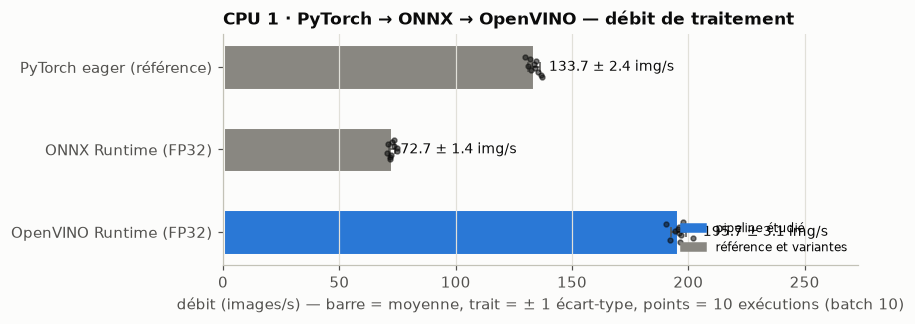

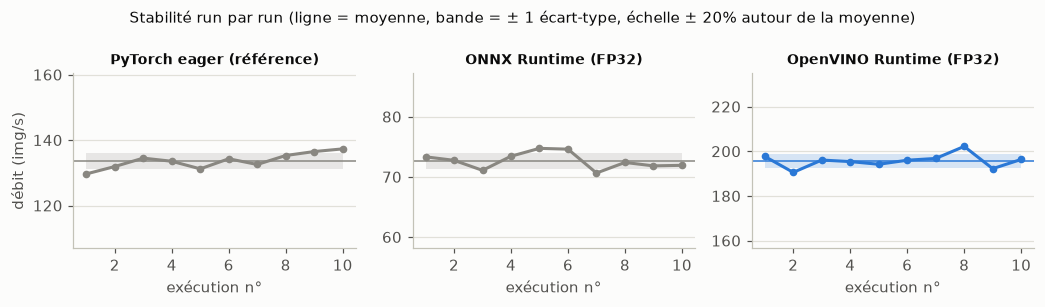

Résultats enregistrés : results/cpu1_openvino.json et results/cpu1_openvino_logits.npz
Hors Colab : archive créée -> cpu1_openvino_sorties.zip


In [15]:
results_df = results_table()
display(results_df)
plot_local_results()
save_results()

# Archive à télécharger (Colab) : à décompresser à la racine du dépôt (dossiers results/ et figures/)
import shutil, zipfile
archive = f"{PIPELINE_ID}_sorties.zip"
with zipfile.ZipFile(archive, "w") as z:
    for folder in (RESULTS_DIR, FIGURES_DIR):
        for path in glob.glob(f"{folder}/{PIPELINE_ID}*"):
            z.write(path)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Hors Colab : archive créée ->", archive)

## Analyse (à compléter à partir de vos résultats)

- **Gain du pipeline** : accélération d'OpenVINO par rapport à PyTorch eager sur ce CPU (rapport des débits moyens). L'écart dépasse-t-il largement la variabilité (écarts-types) ?
- **Format vs runtime** : ONNX Runtime et OpenVINO lisent le même fichier ONNX. Que montre l'écart entre eux sur le rôle du *middle level* ?
- **Fusion et kernels** : nombre de nœuds ONNX → IR → graphe exécuté ; quelles primitives oneDNN ont été retenues et pourquoi dépendent-elles du processeur (`cpu_isa` dans `get_env_info()`) ?
- **Qualité** : Top-1 identique à la référence ? Écart maximal des logits (en FP32, il reste de l'ordre des erreurs d'arrondi) et accord des prédictions.
- **Stabilité** : CV du débit, écart min–max, présence d'exécutions aberrantes (VM partagée, turbo, autres processus).
- **Énergie** : indisponible si la VM n'expose pas RAPL — le signaler dans le rapport.